# Machine learning for neural time series — hands-on

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gon-uri/ITBA2026/blob/main/notebook/ml_neural_ts_notebook.ipynb)

*ITBA · 23 October 2026 · Gonzalo Uribarri (Stockholm University)*

**Two questions.** **Q1 (EEG):** *can a model tell whether your eyes are closed, in a person it has never seen?*
**Q2 (fMRI):** *can it tell a child's brain from an adult's — and is it reading the brain or the head movement?*

**How to work.** In pairs. **Shift+Enter** runs a cell; there is no code to write. Say your guess, then run. If Colab
says "This notebook was not authored by Google", click *Run anyway*. Behind? *Runtime → Run all*.
**When the professor says "jump", go to §6 (fMRI):** it needs only §0.

**Two tasks.** **PREDICT · classify or regress:** learn a label or a number from labelled examples.
**REPRESENT · embed or cluster:** find a compact description of the data without labels. A graph of the channels (a
connectome) is not a third task: it turns a multichannel series into **connectivity features**.

| § | Task | Data | Question |
|---|---|---|---|
| §1 | look | EEG | What changes when the eyes close? |
| §2 | PREDICT · classify (hand-made features) | EEG | Eyes open or closed, in a new person? What does a leaky split do? |
| §3 | REPRESENT · embed or cluster | EEG | What organises 1,200 windows without labels? |
| §4 | PREDICT · classify (random features) | EEG | Can MiniRocket do it from the raw signal, with no spectrum? |
| §6 | PREDICT · classify (connectivity features) | fMRI | Child or adult from a brain graph? Is it head motion? |
| §7 | PREDICT · regress (connectivity features) | fMRI | How old is this brain? |

Section numbers follow the chips on the slides. This version has no section 5 (the Fp1/Fpz/Fp2 check) and no section 8
(the table of your numbers), and its §4 is new (MiniRocket), not the alpha graph cited on the wrap-up slide, where the
lecture numbers of those parts are. Every result prints **your run** next to the **lecture run** (the number on the
slides, or the lecturer's run of the same code); they should agree.

*Data:* EEG — Schalk et al. 2004, EEG Motor Movement/Imagery dataset (PhysioNet), ODC-By 1.0. fMRI — Richardson et al.
2018, OpenNeuro ds000228, preprocessed derivative distributed with nilearn (OSF 5hju4), CC BY 4.0. *Code:* MIT licence.

## §0 · Setup

Install three packages Colab lacks, load the tools, download the data (EEG: 20 people, 64 electrodes, 1 min eyes open
+ 1 min eyes closed, ~51 MB; fMRI: 155 people, 3.9 MB), and cut the EEG into 2-s windows.

In [1]:
# §0.1 · Install MNE (EEG), nilearn (fMRI) and aeon (MiniRocket, §4). Pinned: newer versions upgrade packages Colab
# has already loaded and force a session restart.
%pip install -q mne==1.11.0 nilearn==0.13.1 aeon==1.6.0

In [2]:
# §0.2 · Imports, settings, helpers
import os, json, time, warnings, platform, importlib.resources, concurrent.futures
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy.signal import welch
from scipy.stats import pearsonr
import pooch
import mne
from mne.datasets import eegbci
import nilearn
from nilearn.connectome import ConnectivityMeasure
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, RidgeCV, RidgeClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (GroupKFold, KFold, RepeatedStratifiedKFold, RepeatedKFold, cross_val_score,
                                     cross_val_predict, cross_validate)
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import aeon
from aeon.transformations.collection.convolution_based import MiniRocket

mne.set_log_level("ERROR")
pooch.get_logger().setLevel("WARNING")

SEED = 0                                   # one seed everywhere, so your numbers match the lecture's
if "MNE_DATA" in os.environ:               # where downloads go
    DATA_DIR = Path(os.environ["MNE_DATA"])
elif Path("/content").is_dir():            # Google Colab
    DATA_DIR = Path("/content/data")
else:                                      # your own computer
    DATA_DIR = Path.home() / "mne_data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

SUBJECTS = range(1, 21)                    # 20 volunteers, S001-S020
SFREQ = 160.0                              # samples per second
WIN_S = 2.0                                # window length (s)
OCC = ["O1", "Oz", "O2"]                   # back of the head (visual cortex)
ALPHA = (8, 13)                            # alpha band of the features

NAVY, ORANGE, STEEL, GREYBLUE, OLIVE, LIGHTBLUE = "#002F5F", "#EB7125", "#33587F", "#9BB2CE", "#A3A86B", "#ACDEE6"
EO_C, EC_C = NAVY, ORANGE                  # eyes open = navy, eyes closed = orange
ADULT_C, CHILD_C = NAVY, GREYBLUE          # fMRI groups
plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

REPO_RAW = "https://raw.githubusercontent.com/gon-uri/ITBA2026/main/data/"
SHA256 = {
    "fmri_development_msdl.npz": '9cf96e73b8a8ba1034d32e7f96fc75b9142f1acf3e992ea349d8dabbbdb01518',
    "eoec_features.npz": '48564036f85d8feddb2f791d69da78fb12d17be23f114d61721c5221f16731cf',
}

# Numbers of the lecture run (Lesson/figures/results_*.json); do not edit
EXPECTED = {
    "alpha_ratio_max": 21.12,
    "alpha_ratio_median": 3.37,
    "alpha_ratio_min": 1.12,
    "clf_dummy_most_frequent_honest_mean": 0.5,
    "clf_dummy_most_frequent_honest_sd": 0.0,
    "clf_full_logpsd_64x40_honest_mean": 0.7475,
    "clf_full_logpsd_64x40_honest_per_subject_acc_max": 1.0,
    "clf_full_logpsd_64x40_honest_per_subject_acc_median": 0.733,
    "clf_full_logpsd_64x40_honest_per_subject_acc_min": 0.5,
    "clf_full_logpsd_64x40_honest_sd": 0.1175,
    "clf_full_logpsd_64x40_leaky_mean": 0.9117,
    "clf_full_logpsd_64x40_leaky_sd": 0.0218,
    "clf_leak_gain_full_logpsd_points": 16.4,
    "clf_one_feature_occipital_alpha_mean_logpower_honest_mean": 0.6425,
    "clf_one_feature_occipital_alpha_mean_logpower_honest_sd": 0.0756,
    "cluster_kmeans_raw_k2_ari_eyes": -0.001,
    "cluster_kmeans_raw_k2_ari_person": 0.081,
    "cluster_kmeans_raw_k2_n_people_ge90pct_windows_in_one_cluster": 19,
    "dev_age_all_mae_model_mean_y": 3.5489,
    "dev_age_all_mae_trainmean_baseline_mean_y": 6.1937,
    "dev_age_all_pearson_r_mean": 0.7976,
    "dev_cls_all_dummy_acc_mean": 0.7871,
    "dev_cls_all_dummy_auc_mean": 0.5,
    "dev_cls_all_dummy_bal_acc_mean": 0.5,
    "dev_cls_all_motion_only_bal_acc_mean": 0.6927,
    "dev_cls_all_tangent_acc_mean": 0.9619,
    "dev_cls_all_tangent_auc_mean": 0.9628,
    "dev_cls_all_tangent_bal_acc_mean": 0.9201,
    "dev_cls_all_tangent_bal_acc_sd": 0.0613,
    "dev_cls_matched_motion_only_bal_acc_mean": 0.4317,
    "dev_cls_matched_tangent_bal_acc_mean": 0.9157,
    "dev_fd_mean_adults_mean_mm": 0.1871,
    "dev_fd_mean_children_mean_mm": 0.3707,
    "dev_n_adults": 33,
    "dev_n_children": 122,
    "embed_raw_tsne_silhouette_by_condition": 0.048,
    "embed_raw_tsne_silhouette_by_subject": 0.321,
    "nb_minirocket_n_features": 9996,
    "nb_minirocket_occ3_honest_mean": 0.7517,
    "nb_minirocket_occ3_honest_per_subject_acc_max": 0.9667,
    "nb_minirocket_occ3_honest_per_subject_acc_median": 0.7667,
    "nb_minirocket_occ3_honest_per_subject_acc_min": 0.5333,
    "nb_minirocket_occ3_honest_sd": 0.0486,
    "nb_spectrum_occ3_3x40_honest_mean": 0.7283,
    "nb_spectrum_occ3_3x40_honest_sd": 0.0733,
    "overfit_logpsd_C1_train_acc_mean": 1.0,
}


def num(v, nd=2):
    "Format a number (halves rounded up); no '-0.00', and a true minus sign."
    v = float(v) + np.copysign(1e-9, v)
    s = f"{v:.{nd}f}"
    if float(s) == 0:
        s = f"{0:.{nd}f}"
    return s.replace("-", "−")


CHECK = {}                                 # your numbers, by lecture key


def show(label, value, key, nd=2, unit="", pct=False):
    "Print your number next to the lecture's."
    value = float(value)
    CHECK[key] = value
    p = f" ({100 * value:.0f}%)" if pct else ""
    print(f"{label}: {num(value, nd)}{unit}{p}  · lecture run {num(EXPECTED[key], nd)}{unit}")


def show_cv(label, scores, prefix, nd=2, pct=True):
    "Mean ± SD over the cross-validation folds, next to the lecture's."
    m, s = float(np.mean(scores)), float(np.std(scores))
    CHECK[prefix + "_mean"], CHECK[prefix + "_sd"] = m, s
    p = f" ({100 * m:.0f}%)" if pct else ""
    print(f"{label}: {num(m, nd)} ± {num(s, nd)}{p}  · lecture run "
          f"{num(EXPECTED[prefix + '_mean'], nd)} ± {num(EXPECTED[prefix + '_sd'], nd)}")


def save_check():
    "For the lecturer's automatic check only: does nothing unless ITBA_CHECK is set."
    if os.environ.get("ITBA_CHECK"):
        Path(os.environ["ITBA_CHECK"]).write_text(json.dumps(CHECK, indent=1))


NEEDS = {"y": "§0.4", "logP": "§1", "F_full": "§2.1–§2.2", "acc_full": "§2.1–§2.2", "Fs": "§3.1",
         "fmri_path": "§0.3", "ts": "§6.1"}


def need(*names):
    "Stop with a clear message if an earlier cell has not been run."
    missing = [n for n in names if globals().get(n) is None]
    if missing:
        where = sorted({NEEDS.get(n, "the cells above") for n in missing})
        raise RuntimeError(f"Run {' and '.join(where)} first (missing: {', '.join(missing)}).")


def make_clf(C=1.0):
    "The EEG model: z-score every feature, then logistic regression."
    return Pipeline([("scale", StandardScaler()), ("lr", LogisticRegression(C=C, max_iter=5000))])


CV_PERSON = GroupKFold(n_splits=5)                              # 4 whole people held out per round
CV_SHUFFLED = KFold(n_splits=5, shuffle=True, random_state=SEED)  # windows shuffled: same people in train and test


def cv_acc(F, cv=CV_PERSON, clf=None):
    "Test accuracy in each of the 5 folds (with GroupKFold the groups are the people)."
    return cross_val_score(make_clf() if clf is None else clf, F, y, groups=g if isinstance(cv, GroupKFold) else None,
                           cv=cv, scoring="accuracy")


def get_repo_file(name):
    "Download one small data file of the course repository (once) and check its SHA-256 fingerprint."
    return Path(pooch.retrieve(REPO_RAW + name, known_hash="sha256:" + SHA256[name], fname=name,
                               path=DATA_DIR / "itba2026", progressbar=False))


def fmri_clf(kind):
    "The fMRI model: connectome (fitted on the training people only) -> z-score -> logistic regression."
    return Pipeline([("connectome", ConnectivityMeasure(kind=kind, vectorize=True, discard_diagonal=True)),
                     ("scale", StandardScaler()),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))])


def fmri_cv(est, Xf, yf):
    "5 folds x 10 repeats over people, stratified by group; positive class = adult."
    r = cross_validate(est, Xf, yf, scoring=["accuracy", "balanced_accuracy", "roc_auc"],
                       cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED))
    return {"acc": r["test_accuracy"], "bal_acc": r["test_balanced_accuracy"], "auc": r["test_roc_auc"]}


print(f"Python {platform.python_version()} | numpy {np.__version__} | scipy {scipy.__version__} | "
      f"scikit-learn {sklearn.__version__} | mne {mne.__version__} | nilearn {nilearn.__version__} | "
      f"aeon {aeon.__version__}")
if not (np.__version__.startswith("2.1.") and sklearn.__version__.startswith("1.6.")):
    print("Note: the lecture ran numpy 2.1 and scikit-learn 1.6; with other versions some numbers may differ slightly.")

Python 3.13.17 | numpy 2.1.3 | scipy 1.16.3 | scikit-learn 1.6.1 | mne 1.11.0 | nilearn 0.13.1 | aeon 1.6.0


In [3]:
# §0.3 · Download the fMRI file and the EEG (checked by checksums). On Colab the download runs on Google's computer.
FORCE_FALLBACK = False        # True = skip the EEG download and use the precomputed spectra (14.9 MB, same numbers)

try:                          # fMRI first, so that §6-§7 work even if the EEG step is slow
    fmri_path = get_repo_file("fmri_development_msdl.npz")
    print(f"fMRI: {fmri_path.stat().st_size / 1e6:.1f} MB, sha256 OK")
except Exception as err:
    fmri_path = None
    print(f"fMRI file not available ({type(err).__name__}): run §0.3 again later; §6-§7 will be skipped")

# EEG: 20 people x runs 1 (eyes open) and 2 (eyes closed), from the AWS copy of PhysioNet (MNE's checksums)
S3 = "https://physionet-open.s3.amazonaws.com/eegmmidb/1.0.0/"
EEG_FILES = [f"S{s:03d}/S{s:03d}R{r:02d}.edf" for s in SUBJECTS for r in (1, 2)]
USE_FALLBACK, edf_paths = FORCE_FALLBACK, None
if not USE_FALLBACK:
    try:
        fetcher = pooch.create(path=DATA_DIR / "MNE-eegbci-data" / "files" / "eegmmidb" / "1.0.0",
                               base_url=S3, registry=None, retry_if_failed=3)
        fetcher.load_registry(importlib.resources.files("mne").joinpath("data", "eegbci_checksums.txt"))
        for name in EEG_FILES:            # create the folders first (parallel downloads would race on them)
            (Path(fetcher.abspath) / name).parent.mkdir(parents=True, exist_ok=True)
        downloader = pooch.HTTPDownloader(timeout=60, progressbar=False)
        pool = concurrent.futures.ThreadPoolExecutor(8)     # 8 files at a time
        futures = {name: pool.submit(fetcher.fetch, name, downloader=downloader) for name in EEG_FILES}
        done, not_done = concurrent.futures.wait(futures.values(), timeout=120)
        pool.shutdown(wait=False, cancel_futures=True)
        if not_done or any(f.exception() is not None for f in done):
            USE_FALLBACK = True
            print("EEG download incomplete: switching to the precomputed file")
        else:
            edf_paths = {name: Path(f.result()) for name, f in futures.items()}
    except Exception as err:
        USE_FALLBACK = True
        print(f"EEG download failed ({type(err).__name__}): switching to the precomputed file")

if USE_FALLBACK:              # fallback: precomputed spectra + raw O1/Oz/O2 of the same 1,200 windows (course repository)
    fb_path = get_repo_file("eoec_features.npz")
    print(f"EEG: using the precomputed file (fallback), {fb_path.stat().st_size / 1e6:.1f} MB")
else:
    print(f"EEG: {len(edf_paths)} files, {sum(p.stat().st_size for p in edf_paths.values()) / 1e6:.1f} MB, checksums OK")

fMRI: 3.9 MB, sha256 OK
EEG: 40 files, 51.0 MB, checksums OK


In [4]:
# §0.4 · Load, filter (1-40 Hz, zero-phase), cut into 2-s windows: signal X, label y (1 = eyes closed), person g
WIN = int(WIN_S * SFREQ)                   # samples per window
if not USE_FALLBACK:
    X, y, g = [], [], []
    for s in SUBJECTS:
        for lab, run in ((0, 1), (1, 2)):
            raw = mne.io.read_raw_edf(edf_paths[f"S{s:03d}/S{s:03d}R{run:02d}.edf"], preload=True)
            eegbci.standardize(raw)                        # channel names such as "Fp1", "Oz"
            raw.set_montage("standard_1005")               # electrode positions on a template head
            raw.filter(1.0, 40.0, fir_design="firwin")
            ep = mne.make_fixed_length_epochs(raw, duration=WIN_S, preload=True).get_data(copy=True)
            X.append(ep)
            y += [lab] * len(ep)
            g += [s] * len(ep)
    X, y, g = np.concatenate(X), np.array(y), np.array(g)   # X: (windows, channels, samples), in volts
    ch_names = list(raw.ch_names)
    print(f"X: {X.shape[0]} windows × {X.shape[1]} channels × {X.shape[2]} samples "
          f"= {X.shape[1] * X.shape[2]:,} numbers per window")
else:
    fb = np.load(fb_path, allow_pickle=False)
    assert WIN_S == 2.0, "the precomputed file holds 2-s windows: set WIN_S = 2 (open question 1 needs the EEG download)"
    X = None                               # the 64-channel windows are not in the precomputed file
    y, g = fb["y"], fb["g"]
    ch_names = list(fb["ch_names"])
    print(f"precomputed file: {len(y)} windows × {len(ch_names)} channels (spectra, plus the raw O1/Oz/O2 for §4)")
print(f"{(y == 0).sum()} eyes open, {(y == 1).sum()} eyes closed, {len(np.unique(g))} people")

X: 1200 windows × 64 channels × 320 samples = 20,480 numbers per window
600 eyes open, 600 eyes closed, 20 people


## §1 · Look before you learn

The **power spectrum** says how much of the signal sits at each frequency (Welch's method, 1-Hz steps).
**Predict:** *which frequency band changes when the eyes close — and by the same amount in everyone?*

alpha power, closed / open, median over people: 3.37  · lecture run 3.37
lowest person: 1.12  · lecture run 1.12
highest person: 21.12  · lecture run 21.12


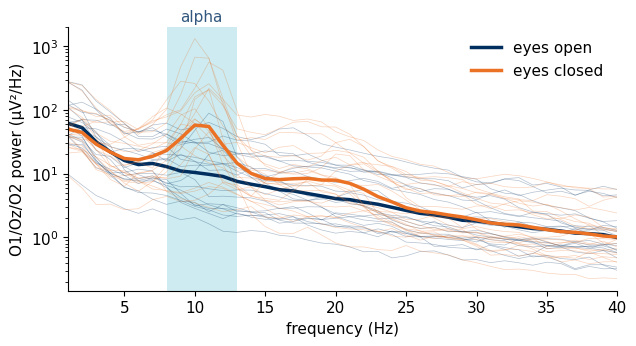

In [5]:
# §1 · Spectrum of every window (1-40 Hz); back-of-head (O1/Oz/O2) spectra, eyes open vs closed
need("y")
if X is not None:
    f_all, P_all = welch(X, fs=SFREQ, nperseg=160, noverlap=80, axis=-1)
    keep = (f_all >= 1) & (f_all <= 40)
    freqs = f_all[keep]
    logP = np.log10(P_all[..., keep] * 1e12)                 # (1200, 64, 40) log10 µV²/Hz
    del P_all
else:
    freqs, logP = fb["f"], fb["logP"].astype(np.float64)
occ = [ch_names.index(c) for c in OCC]


def in_band(lo, hi):
    return (freqs >= lo) & (freqs <= hi)


occ_alpha = (10 ** logP[:, occ][:, :, in_band(*ALPHA)]).mean(axis=(1, 2))     # µV²/Hz per window
ratio = np.array([occ_alpha[(g == s) & (y == 1)].mean() / occ_alpha[(g == s) & (y == 0)].mean() for s in SUBJECTS])
show("alpha power, closed / open, median over people", np.median(ratio), key="alpha_ratio_median")
show("lowest person", ratio.min(), key="alpha_ratio_min")
show("highest person", ratio.max(), key="alpha_ratio_max")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.axvspan(*ALPHA, color=LIGHTBLUE, alpha=0.6, lw=0)
for lab, col, name in ((0, EO_C, "eyes open"), (1, EC_C, "eyes closed")):
    pp = np.array([logP[(g == s) & (y == lab)][:, occ].mean(axis=(0, 1)) for s in SUBJECTS])
    for row in pp:
        ax.plot(freqs, 10 ** row, color=col, lw=0.5, alpha=0.3)
    ax.plot(freqs, 10 ** pp.mean(0), color=col, lw=2.5, label=name)
ax.text(10.5, 1.02, "alpha", transform=ax.get_xaxis_transform(), ha="center", color=STEEL)
ax.set_yscale("log"); ax.set_xlim(1, 40)
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("O1/Oz/O2 power (µV²/Hz)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**What you should see.** With eyes closed, a peak at 8–13 Hz: the **alpha rhythm** (thin lines = single people).
Alpha rises in every person (median ×3.37), but by ×1.12 in one and
×21.12 in another: **people differ more than conditions**. Keep this in mind for §2 and §3.

## §2 · PREDICT: eyes open or closed, tested on new people

**§2.1–§2.2 · One feature vs the whole spectrum.** A **feature** is a number that describes a window; the **label** is
the answer (open or closed). The model, logistic regression, learns one weight per feature from labelled windows.
**Cross-validation by person:** train on 16 people, test on the other 4, five times (`GroupKFold`). The **baseline**
always gives the most common answer.
Features: **1** (mean back-of-head alpha power) or **2,560** (the full spectrum, 64 channels × 40 frequencies).

**Predict:** *what does the baseline score? Do 2,560 features beat 1?*

In [6]:
# §2.1-§2.2 · Two feature sets; baseline, 1 feature and full spectrum, tested on new people
need("logP")
F_one = logP[:, occ][:, :, in_band(*ALPHA)].mean(axis=(1, 2))[:, None]   # 1 feature
F_full = logP.reshape(len(y), -1)                                         # 2,560 features
acc_base = cv_acc(F_full, clf=DummyClassifier(strategy="most_frequent"))
acc_one = cv_acc(F_one)
res_full = cross_validate(make_clf(), F_full, y, groups=g, cv=CV_PERSON, return_train_score=True)
acc_full, acc_full_train = res_full["test_score"], res_full["train_score"]
pred_full = cross_val_predict(make_clf(), F_full, y, groups=g, cv=CV_PERSON)
acc_person = np.array([(pred_full[g == s] == y[g == s]).mean() for s in SUBJECTS])

show_cv("baseline (always the same answer)", acc_base, prefix="clf_dummy_most_frequent_honest")
show_cv("1 feature (occipital alpha)", acc_one, prefix="clf_one_feature_occipital_alpha_mean_logpower_honest")
show_cv("full spectrum (2,560 features)", acc_full, prefix="clf_full_logpsd_64x40_honest")
show("full spectrum, on its own training windows", acc_full_train.mean(), key="overfit_logpsd_C1_train_acc_mean", pct=True)
show("one new person: lowest", acc_person.min(), key="clf_full_logpsd_64x40_honest_per_subject_acc_min")
show("one new person: highest", acc_person.max(), key="clf_full_logpsd_64x40_honest_per_subject_acc_max")
CHECK["clf_full_logpsd_64x40_honest_per_subject_acc_median"] = float(np.median(acc_person))

baseline (always the same answer): 0.50 ± 0.00 (50%)  · lecture run 0.50 ± 0.00
1 feature (occipital alpha): 0.64 ± 0.08 (64%)  · lecture run 0.64 ± 0.08
full spectrum (2,560 features): 0.75 ± 0.12 (75%)  · lecture run 0.75 ± 0.12
full spectrum, on its own training windows: 1.00 (100%)  · lecture run 1.00
one new person: lowest: 0.50  · lecture run 0.50
one new person: highest: 1.00  · lecture run 1.00


**What you should see.** Baseline 0.50; one feature
0.64; full spectrum 0.75 ±
0.12. On its own training windows the same model scores
1.00: only the test score counts. A single new person scores anywhere from
0.50 to 1.00.

**§2.4 · The leak: the same model, with the windows shuffled across people.** Now the 5 folds are made of shuffled
windows, so every person has windows in both training and test.

**Predict:** *higher, lower or the same as 0.75?*

In [7]:
# §2.4 · Same model, same features; folds of shuffled windows (people appear in training and test)
need("acc_full")
acc_leaky = cv_acc(F_full, cv=CV_SHUFFLED)
show_cv("full spectrum, shuffled windows", acc_leaky, prefix="clf_full_logpsd_64x40_leaky")
show("gain over the person split (points)", 100 * (acc_leaky.mean() - acc_full.mean()),
     key="clf_leak_gain_full_logpsd_points", nd=1)

full spectrum, shuffled windows: 0.91 ± 0.02 (91%)  · lecture run 0.91 ± 0.02
gain over the person split (points): 16.4  · lecture run 16.4


**What you should see.** 0.91: +16 points
without learning anything new about eyes. Each person's spectrum is a fingerprint, and the model has already seen that
person's other windows. **Trust check · SPLIT:** test on the unit you want to generalise to — here, a new person.

## §3 · REPRESENT (embed or cluster): what organises the 1,200 windows?

**§3.1 · A map.** **t-SNE** squeezes each window's 2,560 numbers into 2, keeping similar windows close; no labels are
used. **Silhouette** says how well a colouring forms separate groups (1 = tight and separate, 0 = no grouping).

**Predict:** *coloured by eyes, will you see two islands?*

silhouette by person: 0.32  · lecture run 0.32
silhouette by eyes: 0.05  · lecture run 0.05
(t-SNE numbers can differ by about ±0.03 across library versions or computers)


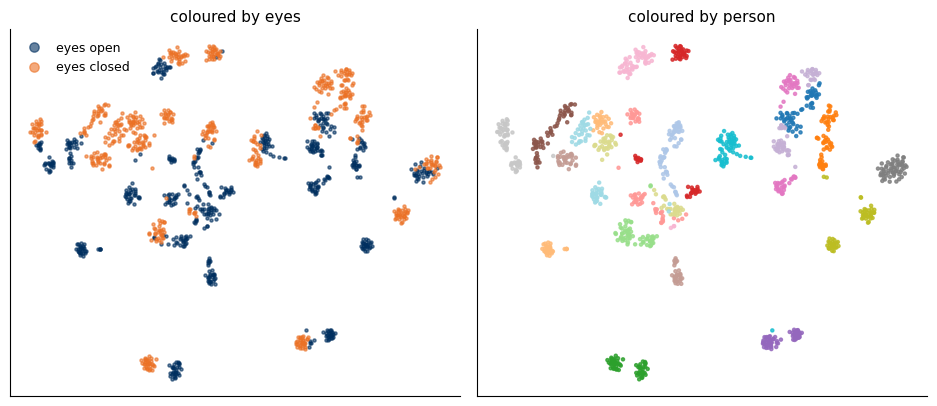

In [8]:
# §3.1 · t-SNE of the z-scored spectra, coloured by eyes and by person (takes ~10 s)
need("F_full")
Fs = StandardScaler().fit_transform(F_full)
Z = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(Fs)
sil_person, sil_eyes = silhouette_score(Z, g), silhouette_score(Z, y)
show("silhouette by person", sil_person, key="embed_raw_tsne_silhouette_by_subject")
show("silhouette by eyes", sil_eyes, key="embed_raw_tsne_silhouette_by_condition")
print("(t-SNE numbers can differ by about ±0.03 across library versions or computers)")
fig, axs = plt.subplots(1, 2, figsize=(9.5, 4.2))
for lab, col, name in ((0, EO_C, "eyes open"), (1, EC_C, "eyes closed")):
    axs[0].scatter(*Z[y == lab].T, s=5, color=col, alpha=0.6, label=name)
axs[1].scatter(*Z.T, s=5, c=g, cmap="tab20", alpha=0.8)
axs[0].set_title("coloured by eyes", fontsize=11); axs[1].set_title("coloured by person", fontsize=11)
axs[0].legend(frameon=False, markerscale=3, fontsize=9)
for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**What you should see.** Coloured by person, islands (silhouette 0.32);
coloured by eyes, both colours mixed inside every island (0.05).
**The islands are people** — which is why the shuffled split of §2.4 looked so good.

**§3.2 · Clustering.** **k-means** groups the windows into k clusters without labels. **ARI** compares two groupings
(0 = chance, 1 = identical). **Predict:** *with k = 2, will the clusters be eyes open and eyes closed?*

In [9]:
# §3.2 · k-means with k = 2 on the same z-scored spectra
need("Fs")
km2 = KMeans(n_clusters=2, n_init=20, random_state=SEED).fit_predict(Fs)
ari_eyes = adjusted_rand_score(y, km2)
show("ARI with eyes", ari_eyes, key="cluster_kmeans_raw_k2_ari_eyes")
show("ARI with person", adjusted_rand_score(g, km2), key="cluster_kmeans_raw_k2_ari_person")
n90 = sum(np.bincount(km2[g == s], minlength=2).max() / (g == s).sum() >= 0.9 for s in SUBJECTS)
show("people with >= 90% of their windows in one cluster", n90,
     key="cluster_kmeans_raw_k2_n_people_ge90pct_windows_in_one_cluster", nd=0)

ARI with eyes: 0.00  · lecture run 0.00
ARI with person: 0.08  · lecture run 0.08
people with >= 90% of their windows in one cluster: 19  · lecture run 19


**What you should see.** No: ARI with eyes 0.00, and
19 of 20 people fall almost entirely in one cluster:
k-means splits the *people*. An unsupervised method finds the biggest source of variation, not necessarily the one you
care about.

## §4 · PREDICT with random features: MiniRocket on the raw signal

So far a person chose the features: the spectrum. **MiniRocket** (Dempster et al. 2021, a faster, almost deterministic
version of ROCKET) computes no spectrum. It slides **84 short filters** (9 samples, fixed weights) along the raw signal,
each spread out to several lengths (**dilations**, up to the whole window). For each filter it takes thresholds from the
outputs on random training windows and keeps the **proportion of time the output is above each threshold** (PPV,
"proportion of positive values"; not the positive predictive value of medical tests). With several electrodes, each
filter (at each dilation) reads a random subset of them (here 1, 2 or all 3) and adds their outputs, so the number of
features does not grow with the electrodes. Result: 9,996 **random features** per window
(random only in which training window sets each threshold and which electrodes each filter reads), none learned from
the labels. Then one linear model learns a weight for each: a **ridge classifier** (a linear model with a penalty on
large weights, whose strength it picks by itself on the training windows), as in the MiniRocket paper. Input: the raw
2-s signal (filtered 1–40 Hz as in §0.4, but no spectrum) of the same 3 back-of-head electrodes (O1, Oz, O2), tested on
new people as in §2.

**Predict:** *one alpha feature from these 3 electrodes gave 0.64,
the full spectrum of all 64 electrodes 0.75. MiniRocket, from 3 electrodes and no
spectrum?*

In [10]:
# §4 · MiniRocket (random features) -> ridge classifier on the raw O1/Oz/O2 windows, tested on new people;
# then the hand-made spectrum of the same 3 electrodes. Takes about a minute on Colab (the first fold also compiles).
need("acc_full")
MR_CHANNELS = OCC                          # the electrodes MiniRocket sees (open question 4: try ch_names)
if X is not None:
    X_mr = X[:, [ch_names.index(c) for c in MR_CHANNELS]]           # (1200, 3, 320) filtered windows, in volts
else:                                      # fallback: rebuild the same windows from the raw O1/Oz/O2 in the file
    assert MR_CHANNELS == OCC, "with the precomputed file only O1, Oz and O2 are available (others need the download)"
    unf, n_samp, win_idx = fb["unf"], fb["n_samples"], fb["w"]      # read each array from the file once
    X_mr = np.zeros((len(y), 3, WIN))
    for i, s in enumerate(SUBJECTS):
        for lab in (0, 1):
            xf = mne.filter.filter_data(unf[i, lab, :3, :n_samp[i, lab]] * 1e-6, SFREQ, 1.0, 40.0, fir_design="firwin")
            for k in np.flatnonzero((g == s) & (y == lab)):
                X_mr[k] = xf[:, WIN * win_idx[k]: WIN * (win_idx[k] + 1)]


def make_minirocket():
    "Random features (MiniRocket), then one linear model (ridge classifier with built-in choice of the penalty)."
    return Pipeline([("minirocket", MiniRocket(n_kernels=10000, random_state=SEED)),
                     ("scale", StandardScaler(with_mean=False)),
                     ("ridge", RidgeClassifierCV(alphas=np.logspace(-3, 3, 10)))])


pred_mr, acc_mr, t0 = np.zeros(len(y), dtype=int), [], time.time()
for k, (tr, te) in enumerate(CV_PERSON.split(X_mr, y, g)):          # the same 5 folds of people as in §2
    model_mr = make_minirocket().fit(X_mr[tr], y[tr])
    pred_mr[te] = model_mr.predict(X_mr[te])
    acc_mr.append((pred_mr[te] == y[te]).mean())
    print(f"fold {k + 1}/5: 4 new people, accuracy {acc_mr[-1]:.2f}  ({time.time() - t0:.0f} s)")
acc_mr_person = np.array([(pred_mr[g == s] == y[g == s]).mean() for s in SUBJECTS])
n_feat = model_mr.named_steps["minirocket"].transform(X_mr[:1]).shape[1]
acc_occ_spec = cv_acc(logP[:, occ].reshape(len(y), -1))            # hand-made: 3 electrodes x 40 frequencies

show("MiniRocket: features per window", n_feat, key="nb_minirocket_n_features", nd=0)
show_cv("MiniRocket, raw " + ("/".join(MR_CHANNELS) if len(MR_CHANNELS) <= 3 else f"{len(MR_CHANNELS)} electrodes"),
        acc_mr, prefix="nb_minirocket_occ3_honest")
show("MiniRocket, one new person: lowest", acc_mr_person.min(), key="nb_minirocket_occ3_honest_per_subject_acc_min")
show("MiniRocket, one new person: highest", acc_mr_person.max(), key="nb_minirocket_occ3_honest_per_subject_acc_max")
CHECK["nb_minirocket_occ3_honest_per_subject_acc_median"] = float(np.median(acc_mr_person))
show_cv("spectrum of the same 3 electrodes (120 features)", acc_occ_spec, prefix="nb_spectrum_occ3_3x40_honest")
print(f"from §2: 1 alpha feature {num(acc_one.mean())} · full spectrum, 64 electrodes {num(acc_full.mean())}")
print("(MiniRocket numbers may differ slightly on another computer)")

fold 1/5: 4 new people, accuracy 0.77  (12 s)


fold 2/5: 4 new people, accuracy 0.72  (15 s)


fold 3/5: 4 new people, accuracy 0.67  (19 s)


fold 4/5: 4 new people, accuracy 0.79  (23 s)


fold 5/5: 4 new people, accuracy 0.80  (26 s)
MiniRocket: features per window: 9996  · lecture run 9996
MiniRocket, raw O1/Oz/O2: 0.75 ± 0.05 (75%)  · lecture run 0.75 ± 0.05
MiniRocket, one new person: lowest: 0.53  · lecture run 0.53
MiniRocket, one new person: highest: 0.97  · lecture run 0.97
spectrum of the same 3 electrodes (120 features): 0.73 ± 0.07 (73%)  · lecture run 0.73 ± 0.07
from §2: 1 alpha feature 0.64 · full spectrum, 64 electrodes 0.75
(MiniRocket numbers may differ slightly on another computer)


**What you should see.** MiniRocket 0.75 ± 0.05: from 3
electrodes and no spectrum, as good as the full spectrum of all 64 (0.75), and about
the same as the hand-made spectrum of the same 3 electrodes (0.73 ±
0.07; the difference is smaller than the spread between folds). Filters fixed in
advance, with thresholds set without the labels, did as well as the spectrum without being told what alpha is. A single
new person still scores anywhere from 0.53 to
0.97. The price: 9,996 features that are
hard to read one by one. **Q1:** yes, about 3 times in 4 for a new person, with hand-made or with random features.

## §6 · fMRI: child or adult from a brain graph — and is it head motion?

**Jump here** when the professor says so; needs only §0.

**§6.1 · The data.** 155 people watching the same short film. BOLD fMRI is a slow echo of neural
activity, here one image every 2 s. An atlas (MSDL) pools the voxels into 39 regions,
so each person is a 39-channel time series; correlating every pair of regions gives a **connectome**
with 741 edges (connectivity features).

In [11]:
# §6.1 · Region time series, age, group and head motion of 155 people
need("fmri_path")
dev = np.load(fmri_path, allow_pickle=False)
ts = dev["ts"].astype(np.float64)                     # (people, images, regions)
age = dev["age"].astype(float)
is_adult = dev["child_adult"] == "adult"
y_dev = is_adult.astype(int)                          # 1 = adult (the positive class), 0 = child
fd_mean = dev["fd_mean"].astype(float)                # mean framewise displacement (mm)
n_p, n_t, n_r = ts.shape
print(f"{n_p} people, {n_t} images, {n_r} regions -> {n_r * (n_r - 1) // 2} edges")
show("children", (~is_adult).sum(), key="dev_n_children", nd=0)
show("adults", is_adult.sum(), key="dev_n_adults", nd=0)

155 people, 168 images, 39 regions -> 741 edges
children: 122  · lecture run 122
adults: 33  · lecture run 33


**§6.3–§6.4 · "Always child" vs the connectome.** **Balanced accuracy** = the mean of the accuracy within each group
(children, adults); 0.50 = chance. **AUC**: 0.5 = chance, 1 = perfect. The model: tangent-space connectome → logistic
regression, tested over people (5 folds × 10 repeats; the connectome's group average is fitted on training people only).

**Predict:** *the accuracy of a model that always says "child"?*

In [12]:
# §6.3-§6.4 · "Always child" and the tangent connectome -> logistic regression (50 test folds)
need("ts")
res_dummy = fmri_cv(DummyClassifier(strategy="most_frequent"), fd_mean[:, None], y_dev)
res_tan = fmri_cv(fmri_clf("tangent"), ts, y_dev)
show('"always child": accuracy', res_dummy["acc"].mean(), key="dev_cls_all_dummy_acc_mean", pct=True)
show('"always child": balanced accuracy', res_dummy["bal_acc"].mean(), key="dev_cls_all_dummy_bal_acc_mean")
show("connectome: accuracy", res_tan["acc"].mean(), key="dev_cls_all_tangent_acc_mean")
show_cv("connectome: balanced accuracy", res_tan["bal_acc"], prefix="dev_cls_all_tangent_bal_acc")
show("connectome: AUC", res_tan["auc"].mean(), key="dev_cls_all_tangent_auc_mean")
CHECK["dev_cls_all_dummy_auc_mean"] = float(res_dummy["auc"].mean())

"always child": accuracy: 0.79 (79%)  · lecture run 0.79
"always child": balanced accuracy: 0.50  · lecture run 0.50
connectome: accuracy: 0.96  · lecture run 0.96
connectome: balanced accuracy: 0.92 ± 0.06 (92%)  · lecture run 0.92 ± 0.06
connectome: AUC: 0.96  · lecture run 0.96


**What you should see.** "Always child" scores accuracy 0.79 with no knowledge (the share
of children) but balanced accuracy 0.50. The connectome: balanced accuracy
0.92 ± 0.06, AUC 0.96.
**Trust check · METRIC:** with unequal groups, accuracy hides the small group.

**§6.5 · Is it just head motion?** Children move more in the scanner, and motion changes correlations. Mean
**framewise displacement** (FD) = head movement from one image to the next (mm). We test motion alone, then the same
models on a subset where children and adults move equally.

**Predict:** *does the connectome still work when motion is matched?*

In [13]:
# §6.5 · A motion-only model, then motion-only and connectome on a motion-matched subset
need("ts")
show("mean FD, children (mm)", fd_mean[~is_adult].mean(), key="dev_fd_mean_children_mean_mm")
show("mean FD, adults (mm)", fd_mean[is_adult].mean(), key="dev_fd_mean_adults_mean_mm")
motion_clf = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))])
res_motion = fmri_cv(motion_clf, fd_mean[:, None], y_dev)
show("motion only, all 155: balanced accuracy", res_motion["bal_acc"].mean(), key="dev_cls_all_motion_only_bal_acc_mean")

# all 33 adults + the 33 children with the closest motion (greedy, without replacement)
adults_idx, available, matched_children = np.flatnonzero(is_adult), list(np.flatnonzero(~is_adult)), []
for a in adults_idx[np.argsort(fd_mean[adults_idx], kind="stable")]:      # adults from lowest to highest motion
    matched_children.append(available.pop(int(np.argmin(np.abs(fd_mean[available] - fd_mean[a])))))
sub = np.r_[adults_idx, np.sort(matched_children)]
res_m_motion = fmri_cv(motion_clf, fd_mean[sub, None], y_dev[sub])
res_m_tan = fmri_cv(fmri_clf("tangent"), ts[sub], y_dev[sub])
show(f"motion-matched ({len(sub)} people), motion only: balanced accuracy", res_m_motion["bal_acc"].mean(),
     key="dev_cls_matched_motion_only_bal_acc_mean")
show(f"motion-matched ({len(sub)} people), connectome: balanced accuracy", res_m_tan["bal_acc"].mean(),
     key="dev_cls_matched_tangent_bal_acc_mean")

mean FD, children (mm): 0.37  · lecture run 0.37
mean FD, adults (mm): 0.19  · lecture run 0.19
motion only, all 155: balanced accuracy: 0.69  · lecture run 0.69


motion-matched (66 people), motion only: balanced accuracy: 0.43  · lecture run 0.43
motion-matched (66 people), connectome: balanced accuracy: 0.92  · lecture run 0.92


**What you should see.** Children move about twice as much (FD 0.37 vs
0.19 mm), and motion alone reaches balanced accuracy 0.69.
With motion matched (66 people), motion no longer predicts the group
(0.43), but the connectome still does (0.92).
**Q2:** yes — on one site, one film and two age groups far apart. **Trust check · CONFOUND.**

## §7 · fMRI: PREDICT a number — how old is this brain?

**§7.1 · Regression: age from the connectome.** The output is now a number. **Ridge regression** = a linear model with
a penalty on large weights. **MAE** = mean error in years. The baseline always predicts the training people's mean age.

**Predict:** *the baseline is off by about 6 years. The connectome?*

MAE, connectome (years): 3.5  · lecture run 3.5
MAE, always the mean age (years): 6.2  · lecture run 6.2
Pearson r, predicted vs true age: 0.80  · lecture run 0.80


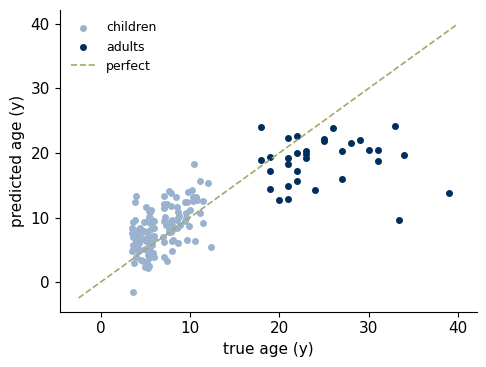

In [14]:
# §7.1 · Tangent connectome -> ridge regression of age; 5 folds x 10 repeats over people
need("ts")
mae, mae0, r_, oof = [], [], [], np.zeros((10, n_p))
for k, (tr, te) in enumerate(RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED).split(ts)):
    m = Pipeline([("connectome", ConnectivityMeasure(kind="tangent", vectorize=True, discard_diagonal=True)),
                  ("scale", StandardScaler()), ("ridge", RidgeCV(alphas=np.logspace(-3, 3, 13)))]).fit(ts[tr], age[tr])
    p = m.predict(ts[te])
    oof[k // 5, te] = p
    mae.append(np.mean(np.abs(p - age[te])))
    mae0.append(np.mean(np.abs(age[tr].mean() - age[te])))     # always the training mean age
    r_.append(pearsonr(p, age[te])[0])
show("MAE, connectome (years)", np.mean(mae), key="dev_age_all_mae_model_mean_y", nd=1)
show("MAE, always the mean age (years)", np.mean(mae0), key="dev_age_all_mae_trainmean_baseline_mean_y", nd=1)
show("Pearson r, predicted vs true age", np.mean(r_), key="dev_age_all_pearson_r_mean")
pred = oof.mean(0)                                            # out-of-fold prediction, mean over repeats
fig, ax = plt.subplots(figsize=(5, 3.8))
ax.scatter(age[~is_adult], pred[~is_adult], s=16, color=CHILD_C, label="children")
ax.scatter(age[is_adult], pred[is_adult], s=16, color=ADULT_C, label="adults")
lim = [min(age.min(), pred.min()) - 1, max(age.max(), pred.max()) + 1]
ax.plot(lim, lim, color=OLIVE, ls="--", lw=1.2, label="perfect")
ax.set_xlabel("true age (y)"); ax.set_ylabel("predicted age (y)"); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
save_check()   # for the lecturer's automatic check only; does nothing otherwise

**What you should see.** Off by 3.5 years against
6.2 for the mean age (r 0.80); much of it is
the child–adult gap, but it also works within the children alone (lecture run: 1.3
vs 2.0 y). **Trust check · BASELINE.**

## Open questions (optional, at home)

1. **Window length.** Set `WIN_S = 1` or `4` in §0.2 and re-run §0.4–§2.4 (this needs the EEG download, not the
   precomputed file). What happens to the gap between the person split and the shuffled split? Why?
2. **Name the trust check.** For §2.4 (shuffled windows) and §6.3 ("always child" accuracy): which trust check fails,
   and what leaked or was hidden?
3. **A different graph.** In §6.3–§6.4 replace `"tangent"` by `"correlation"` or `"partial correlation"`. Which graph
   predicts better? Why could removing indirect links predict *worse*?
4. **MiniRocket with more electrodes.** In §4 set `MR_CHANNELS = ch_names` (all 64; this needs the EEG download, not
   the precomputed file). Does it beat the 3 back-of-head electrodes? How much longer does it take? (Hint: each filter
   reads at most 9 electrodes, chosen at random.)

## Go further

- **Course repository** (this notebook, the data files, the figure scripts): <https://github.com/gon-uri/ITBA2026>.
  The resources page with all references and links is shared separately.
- **MNE-Python tutorials** (EEG/MEG): <https://mne.tools/stable/auto_tutorials/index.html>
- **nilearn examples** (fMRI, connectomes, decoding): <https://nilearn.github.io/stable/auto_examples/index.html>
- **Neuromatch Academy**, Computational Neuroscience course (free, open materials): <https://compneuro.neuromatch.io>

*Credits.* Data: Schalk et al. 2004 (PhysioNet; Goldberger et al. 2000); Richardson et al. 2018 (OpenNeuro ds000228;
nilearn derivative). Methods: MSDL atlas — Varoquaux et al. 2011; tangent space — Barachant et al. 2012, Dadi et al.
2019; t-SNE — van der Maaten & Hinton 2008; ROCKET — Dempster, Petitjean & Webb 2020; MiniRocket — Dempster, Schmidt &
Webb 2021. Software: MNE-Python (Gramfort et al. 2013), scikit-learn (Pedregosa et al. 2011), nilearn (Abraham et al.
2014), aeon (Middlehurst et al. 2024), numpy, scipy, pandas, matplotlib, pooch.